In [2]:
import torch
import torch.nn as nn
from torchvision.models import resnet18, ResNet18_Weights

In [2]:
base_model = resnet18(weights=ResNet18_Weights.DEFAULT)
print(base_model)

ResNet(
  (conv1): Conv2d(3, 64, kernel_size=(7, 7), stride=(2, 2), padding=(3, 3), bias=False)
  (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
  (relu): ReLU(inplace=True)
  (maxpool): MaxPool2d(kernel_size=3, stride=2, padding=1, dilation=1, ceil_mode=False)
  (layer1): Sequential(
    (0): BasicBlock(
      (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      (relu): ReLU(inplace=True)
      (conv2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn2): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    )
    (1): BasicBlock(
      (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_sta

In [3]:
from PIL import Image
import torchvision.transforms as transforms

### Mel 128 bonafide image

In [5]:
model = resnet18(weights=ResNet18_Weights.DEFAULT).eval()

activations = {}
def hook_fn(module, inp, out):
    activations["layer4"] = out.detach()

handle = model.layer4.register_forward_hook(hook_fn)

preprocess = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),
])

img = Image.open("mel128_bonafide.png").convert("RGB")
x = preprocess(img).unsqueeze(0)

with torch.no_grad():
    logits = model(x)

handle.remove()
feat = activations["layer4"][0]  # shape: [512, 7, 7]

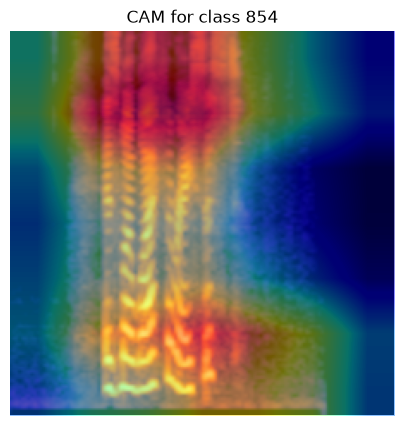

In [7]:
import numpy as np
import matplotlib.pyplot as plt

pred_class = logits.argmax(dim=1).item()
weights = model.fc.weight[pred_class].detach()  # [512]

# Weighted sum across the 512 channels -> [7, 7]
cam = torch.einsum("c,chw->hw", weights, feat).clamp(min=0)
cam = (cam - cam.min()) / (cam.max() - cam.min() + 1e-8)
cam_np = cam.cpu().numpy()

fig, ax = plt.subplots(figsize=(5, 5))
ax.imshow(img.resize((224, 224)))
ax.imshow(cam_np, cmap="jet", alpha=0.45, interpolation="bilinear", extent=(0, 224, 224, 0))
ax.set_title(f"CAM for class {pred_class}")
ax.axis("off")
plt.show()

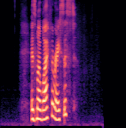

### Mel 128 spoofed image

In [8]:
img = Image.open("mel128_spoofed.png").convert("RGB")
x = preprocess(img).unsqueeze(0)

with torch.no_grad():
    logits = model(x)

handle.remove()
feat = activations["layer4"][0]  # shape: [512, 7, 7]

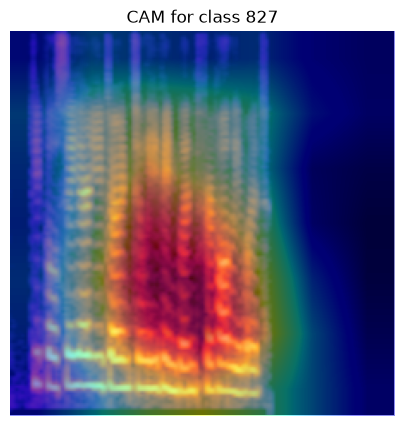

In [9]:
pred_class = logits.argmax(dim=1).item()
weights = model.fc.weight[pred_class].detach()  # [512]

# Weighted sum across the 512 channels -> [7, 7]
cam = torch.einsum("c,chw->hw", weights, feat).clamp(min=0)
cam = (cam - cam.min()) / (cam.max() - cam.min() + 1e-8)
cam_np = cam.cpu().numpy()

fig, ax = plt.subplots(figsize=(5, 5))
ax.imshow(img.resize((224, 224)))
ax.imshow(cam_np, cmap="jet", alpha=0.45, interpolation="bilinear", extent=(0, 224, 224, 0))
ax.set_title(f"CAM for class {pred_class}")
ax.axis("off")
plt.show()